In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Carregando os dados (mantendo o teu código atual)
df = pd.read_csv('train.csv')

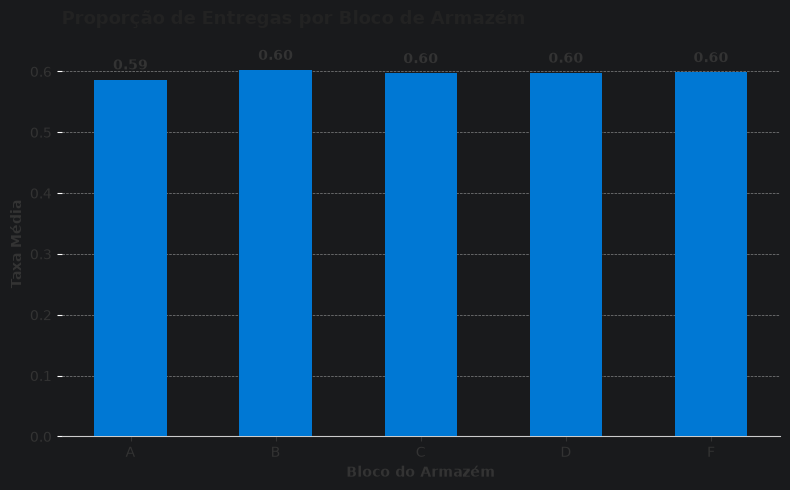

In [2]:
atraso_por_bloco = (
    df.groupby('Warehouse_block')['Reached.on.Time_Y.N'].mean().reset_index()
)

# Configurando a figura
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)

# Criando o gráfico de barras com uma cor corporativa elegante (#0078D4)
barras = ax.bar(
    atraso_por_bloco['Warehouse_block'],
    atraso_por_bloco['Reached.on.Time_Y.N'],
    color='#0078D4',
    width=0.5,
    zorder=3,
)

# Estilo "Clean" (removendo bordas desnecessárias)
for spine in ['top', 'right', 'left']:
  ax.spines[spine].set_visible(False)

ax.spines['bottom'].set_color('#CCCCCC')
ax.grid(axis='y', linestyle='--', alpha=0.6, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)

# Adicionando os valores em cima de cada barra
for barra in barras:
  altura = barra.get_height()
  ax.annotate(
      f'{altura:.2f}',
      xy=(barra.get_x() + barra.get_width() / 2, altura),
      xytext=(0, 5),
      textcoords='offset points',
      ha='center',
      va='bottom',
      fontsize=10,
      color='#333333',
      weight='bold',
  )

# Títulos e rótulos
plt.title(
    'Proporção de Entregas por Bloco de Armazém',
    fontsize=13,
    weight='bold',
    pad=20,
    color='#222222',
    loc='left',
)
plt.xlabel('Bloco do Armazém', fontsize=10, color='#333333', weight='bold')
plt.ylabel('Taxa Média', fontsize=10, color='#333333', weight='bold')
plt.tick_params(axis='x', colors='#333333', labelsize=10)
plt.yticks(color='#333333')

plt.tight_layout()
plt.show()

In [3]:
atrasos_por_envio = pd.crosstab(
    df['Mode_of_Shipment'], df['Reached.on.Time_Y.N']
)

print(atrasos_por_envio)

Reached.on.Time_Y.N     0     1
Mode_of_Shipment               
Flight                708  1069
Road                  725  1035
Ship                 3003  4459


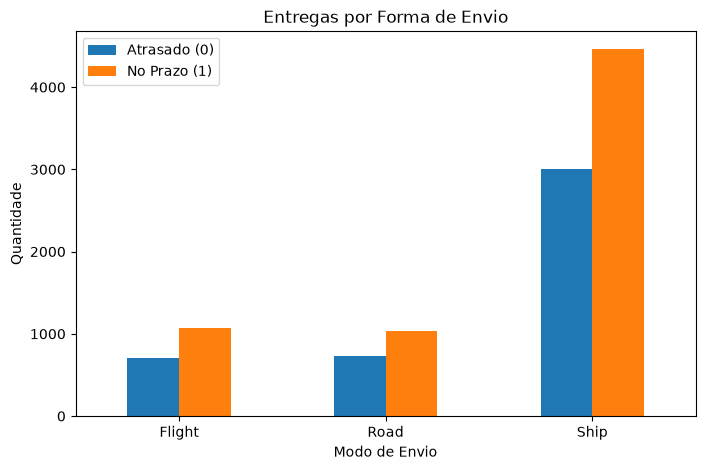

In [4]:
atrasos_por_envio.plot(kind='bar', figsize=(8, 5))

plt.title('Entregas por Forma de Envio')
plt.xlabel('Modo de Envio')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)  # Deixa o nome dos envios retinhos
plt.legend(
    ['Atrasado (0)', 'No Prazo (1)']
)  # Legenda para sabermos quem é quem
plt.show()

In [6]:
# ==========================================
# ANÁLISE 4: Peso Médio vs Atraso
# ==========================================

# Calcula o peso médio dos produtos que atrasaram (0) e dos que chegaram no prazo (1)
peso_por_atraso = (
    df.groupby('Reached.on.Time_Y.N')['Weight_in_gms'].mean().reset_index()
)

print('Peso médio (em gramas) por status de entrega:')
print(peso_por_atraso)

# Criando um gráfico de barras simples


Peso médio (em gramas) por status de entrega:
   Reached.on.Time_Y.N  Weight_in_gms
0                    0    4168.668395
1                    1    3272.640104


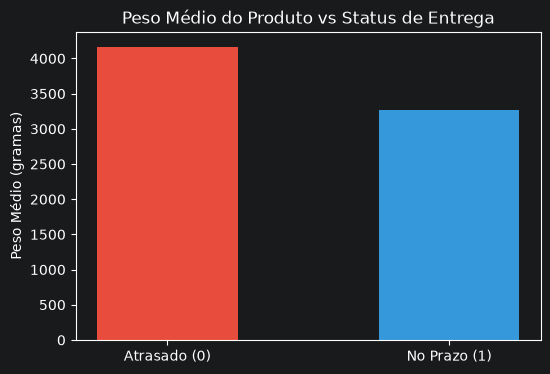

In [7]:
plt.figure(figsize=(6, 4))
plt.bar(
    ['Atrasado (0)', 'No Prazo (1)'],
    peso_por_atraso['Weight_in_gms'],
    color=['#e74c3c', '#3498db'],
    width=0.5,
)

plt.title('Peso Médio do Produto vs Status de Entrega')
plt.ylabel('Peso Médio (gramas)')
plt.show()

In [9]:
avaliacao_por_atraso = (
    df.groupby("Reached.on.Time_Y.N")["Customer_rating"].mean().reset_index()
)
print("avaliação media por atraso :")
print(avaliacao_por_atraso)

avaliação media por atraso :
   Reached.on.Time_Y.N  Customer_rating
0                    0         2.967989
1                    1         3.005790


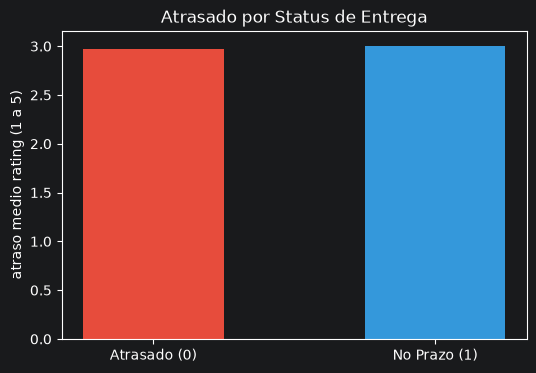

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(
     ['Atrasado (0)', 'No Prazo (1)'],
    avaliacao_por_atraso['Customer_rating'],
    color=['#e74c3c', '#3498db'],
    width=0.5
)
plt.title('Atrasado por Status de Entrega')
plt.ylabel('atraso medio rating (1 a 5)')
plt.show()



In [3]:
# ==========================================
# PREPARAÇÃO PARA MACHINE LEARNING
# ==========================================

# 1. Vamos remover a coluna 'ID' porque ela é apenas um número de série
# e não ajuda o modelo a prever se vai haver atraso ou não.
df_processado = df.drop(columns=['ID'])

# 2. Transformamos todas as colunas de texto em colunas numéricas (0 e 1)
df_ml = pd.get_dummies(df_processado)

# 3. Mostramos as primeiras colunas para ver como ficou
print('Colunas novas criadas pelo One-Hot Encoding:')
print(df_ml.head())

Colunas novas criadas pelo One-Hot Encoding:
   Customer_care_calls  Customer_rating  Cost_of_the_Product  Prior_purchases  \
0                    4                2                  177                3   
1                    4                5                  216                2   
2                    2                2                  183                4   
3                    3                3                  176                4   
4                    2                2                  184                3   

   Discount_offered  Weight_in_gms  Reached.on.Time_Y.N  Warehouse_block_A  \
0                44           1233                    1              False   
1                59           3088                    1              False   
2                48           3374                    1               True   
3                10           1177                    1              False   
4                46           2484                    1              False   


In [4]:
# ==========================================
# 1. SEPARAR FEATURES (X) E TARGET (y)
# ==========================================

# A nossa resposta alvo é saber se chegou no prazo ou não
y = df_ml['Reached.on.Time_Y.N']

# Tudo o resto (exceto a coluna alvo) são as caraterísticas que o modelo vai usar para prever
X = df_ml.drop(columns=['Reached.on.Time_Y.N'])

print('Tamanho das variáveis de entrada (X):', X.shape)
print('Tamanho da variável alvo (y):', y.shape)

Tamanho das variáveis de entrada (X): (10999, 19)
Tamanho da variável alvo (y): (10999,)


In [5]:
# ==========================================
# 2. DIVISÃO EM TREINO E TESTE
# ==========================================
from sklearn.model_selection import train_test_split

# Separamos 80% para treino e 20% para teste
# random_state serve para garantir que a divisão seja sempre igual se você rodar de novo
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Tamanho dos dados de treino (X_train):', X_train.shape)
print('Tamanho dos dados de teste (X_test):', X_test.shape)

Tamanho dos dados de treino (X_train): (8799, 19)
Tamanho dos dados de teste (X_test): (2200, 19)


In [6]:
# ==========================================
# 3. TREINAR O MODELO DE MACHINE LEARNING
# ==========================================
from sklearn.tree import DecisionTreeClassifier

# Criamos o modelo (o "cérebro" vazio)
modelo = DecisionTreeClassifier(random_state=42)

# Treinamos o modelo usando os dados de treino (aqui ele aprende os padrões)
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [7]:
# ==========================================
# 4. AVALIAR O MODELO (PRECISÃO)
# ==========================================
from sklearn.metrics import accuracy_score

# Pedimos ao modelo para prever os resultados usando os dados de teste
previsoes = modelo.predict(X_test)

# Comparamos as previsões do modelo com as respostas reais (y_test)
precisao = accuracy_score(y_test, previsoes)

print(f"Taxa de acerto (Acurácia) do modelo: {precisao * 100:.2f}%")

Taxa de acerto (Acurácia) do modelo: 64.09%


In [8]:
# ==========================================
# TESTANDO UM NOVO MODELO: RANDOM FOREST
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Criamos uma "floresta" com 100 árvores de decisão
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinamos com os mesmos dados de treino
modelo_rf.fit(X_train, y_train)

# Fazemos as previsões com os dados de teste
previsoes_rf = modelo_rf.predict(X_test)

# Calculamos a nova acurácia
precisao_rf = accuracy_score(y_test, previsoes_rf)

print(f'Nova taxa de acerto com Random Forest: {precisao_rf * 100:.2f}%')

Nova taxa de acerto com Random Forest: 65.27%


In [9]:
# Extrai a importância de cada coluna calculada pelo modelo Random Forest
importancias = modelo_rf.feature_importances_

# Junta os nomes das colunas com os respetivos valores de importância
df_importancias = pd.DataFrame(
    {'Variavel': X_train.columns, 'Importancia': importancias}
)

# Ordena da mais importante para a menos importante
df_importancias = df_importancias.sort_values(by='Importancia', ascending=False)

print('Top variáveis mais importantes para o modelo:')
print(df_importancias.head(10))

Top variáveis mais importantes para o modelo:
                     Variavel  Importancia
5               Weight_in_gms     0.266298
4            Discount_offered     0.221118
2         Cost_of_the_Product     0.169882
3             Prior_purchases     0.063647
1             Customer_rating     0.060129
0         Customer_care_calls     0.054618
10          Warehouse_block_F     0.015731
13      Mode_of_Shipment_Ship     0.015000
15     Product_importance_low     0.014089
16  Product_importance_medium     0.013892


Text(0, 0.5, 'Variáveis')

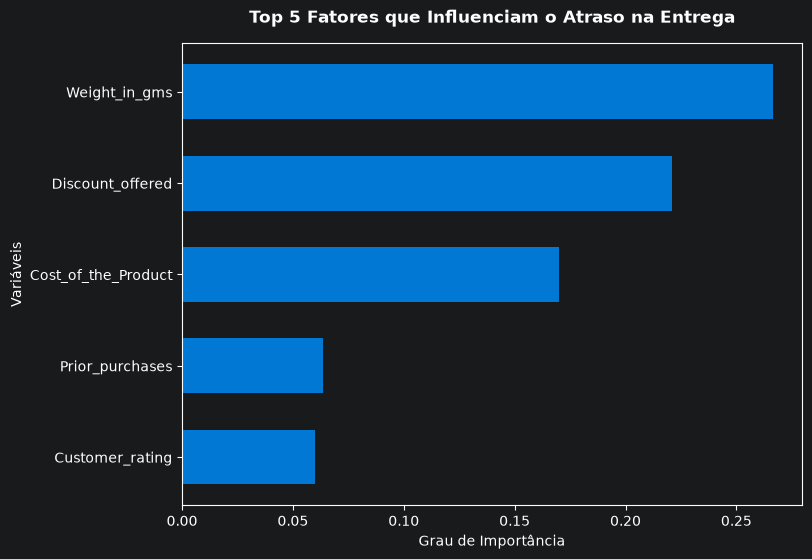

In [10]:
top5 = df_importancias.head(5)
plt.figure(figsize=(8, 6))
plt.barh(
    top5['Variavel'],
    top5['Importancia'],color='#0078D4', height=0.6
)
plt.gca().invert_yaxis()

# Títulos e rótulos limpos
plt.title(
    'Top 5 Fatores que Influenciam o Atraso na Entrega',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Grau de Importância', fontsize=10)
plt.ylabel('Variáveis', fontsize=10)

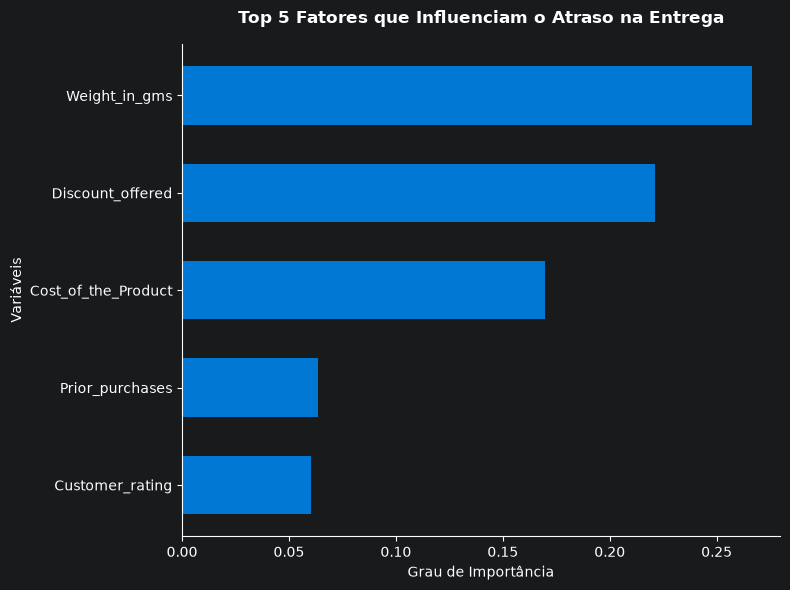

In [19]:
top5 = df_importancias.head(5)
plt.figure(figsize=(8, 6))
plt.barh(
    top5['Variavel'],
    top5['Importancia'],color='#0078D4', height=0.6
)
plt.gca().invert_yaxis()

# Títulos e rótulos limpos
plt.title(
    'Top 5 Fatores que Influenciam o Atraso na Entrega',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Grau de Importância', fontsize=10)
plt.ylabel('Variáveis', fontsize=10)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
maior_taxa_de_atraso = (
    df.groupby('Mode_of_Shipment')['Reached.on.Time_Y.N'].mean()
)
print(maior_taxa_de_atraso)

Mode_of_Shipment
Flight    0.601576
Road      0.588068
Ship      0.597561
Name: Reached.on.Time_Y.N, dtype: float64


In [11]:
plt.figure(figsize=(8, 6))
plt.barh(
    maior_taxa_de_atraso.index,maior_taxa_de_atraso.values
)
plt.xlabel("modo de envio", fontsize=10)
plt.ylabel("taxa de atraso por modo de envio")
plt.show()

NameError: name 'maior_taxa_de_atraso' is not defined

<Figure size 800x600 with 0 Axes>

In [3]:
qtd_acima_250 = len(df[df['Cost_of_the_Product'] > 250])
print(qtd_acima_250)

2778


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

modelo_lr = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr.fit(X_train, y_train)

previsoes_lr = modelo_lr.predict(X_test)

# AQUI ESTÁ O AJUSTE: Comparamos com y_test (respostas reais do teste)
precisao_lr = accuracy_score(y_test, previsoes_lr)

print(f'Taxa de acerto (Acurácia) do modelo: {precisao_lr * 100:.2f}%')

In [ ]:
# ==========================================
# TESTANDO O MODELO COM UM PACOTE NOVO
# ==========================================

# 1. Escolhemos a primeira linha dos nossos dados de teste (um pacote aleatório)
indice = 1

pacote_teste = X_test.iloc[[indice]]
predicao = modelo_rf.predict(pacote_teste)

# Usas exatamente o mesmo índice para ir buscar o gabarito real certo
realidade = y_test.iloc[indice]

print('O modelo previu:', predicao[0])
print('A realidade foi:', realidade)

In [32]:
importancia_por_atraso = (df.groupby("Product_importance")["Reached.on.Time_Y.N"].mean().reset_index())
print(importancia_por_atraso)



  Product_importance  Reached.on.Time_Y.N
0               high             0.649789
1                low             0.592788
2             medium             0.590450


In [35]:
filtro = len(df[df['Discount_offered']> 10])
print(filtro)

2647


In [43]:
modelo_2 = DecisionTreeClassifier(max_depth=6
                                  , random_state=42)
modelo_2.fit(X_train, y_train)
previsao_2 = modelo_2.predict(X_test)
precisao_2 = accuracy_score(y_test, previsao_2)
print(f"A acuracia foi de {precisao_2* 100:.2f}%")


A acuracia foi de 68.05%


Contagem por bloco:
Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64


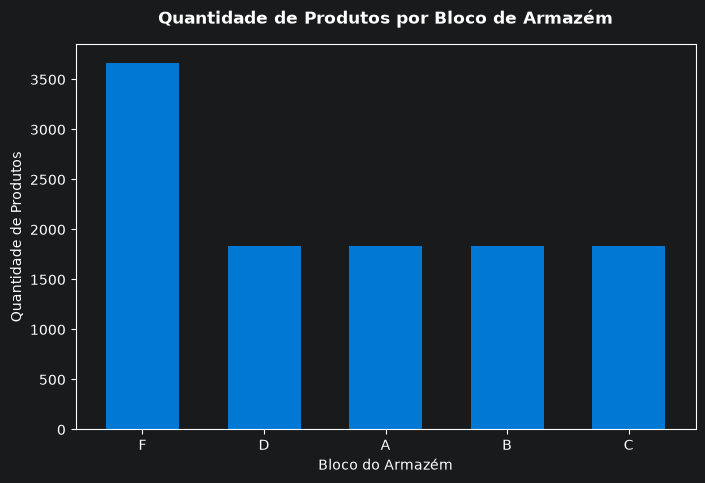

In [25]:
contagem_blocos = df['Warehouse_block'].value_counts()

print("Contagem por bloco:")
print(contagem_blocos)

# 2. Configura o tamanho da figura do gráfico
plt.figure(figsize=(8, 5))

# 3. Plota o gráfico de barras diretamente usando o pandas/matplotlib
contagem_blocos.plot(kind='bar', color='#0078D4', width=0.6)

# 4. Adiciona título e rótulos para ficar organizado
plt.title(
    'Quantidade de Produtos por Bloco de Armazém', fontsize=12, weight='bold', pad=15
)
plt.xlabel('Bloco do Armazém', fontsize=10)
plt.ylabel('Quantidade de Produtos', fontsize=10)
plt.xticks(rotation=0)  # Mantém as letras dos blocos (A, B, C...) retinhas

# 5. Mostra o gráfico na tela
plt.show()



In [14]:
# ==========================================
# MATRIZ DE CONFUSÃO E RELATÓRIO DE CLASSIFICAÇÃO
# ==========================================
from sklearn.metrics import classification_report, confusion_matrix

# 1. Geramos a Matriz de Confusão com base nas previsões da nossa Random Forest
matriz = confusion_matrix(y_test, previsoes_rf)

print('--- Matriz de Confusão ---')
print(matriz)

print('\n--- Relatório Detalhado (Precision e Recall) ---')
# Este relatório mostra exatamente a taxa de acerto separada para quem atrasou (0) e quem chegou no prazo (1)
print(classification_report(y_test, previsoes_rf))

--- Matriz de Confusão ---
[[603 292]
 [472 833]]

--- Relatório Detalhado (Precision e Recall) ---
              precision    recall  f1-score   support

           0       0.56      0.67      0.61       895
           1       0.74      0.64      0.69      1305

    accuracy                           0.65      2200
   macro avg       0.65      0.66      0.65      2200
weighted avg       0.67      0.65      0.66      2200



In [18]:
# ==========================================
# RANDOM FOREST OTIMIZADA PARA SUBIR A ACURÁCIA
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Criamos um modelo mais robusto ajustando os parâmetros:
# - n_estimators=200: Dobramos o número de árvores na floresta
# - max_depth=12: Permitimos que as árvores aprofundem um pouco mais a lógica
# - min_samples_split=5: Evita que o modelo decore os dados à toa
modelo_otimizado = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_split=9, random_state=2
)

# Treinamos com os dados de treino
modelo_otimizado.fit(X_train, y_train)

# Fazemos as previsões com os dados de teste
previsoes_otimizadas = modelo_otimizado.predict(X_test)

# Calculamos a nova acurácia
nova_precisao = accuracy_score(y_test, previsoes_otimizadas)

print(f'🚀 Nova Acurácia Otimizada: {nova_precisao * 100:.2f}%')

print('\n--- Relatório Detalhado Atualizado ---')
print(classification_report(y_test, previsoes_otimizadas))

🚀 Nova Acurácia Otimizada: 67.77%

--- Relatório Detalhado Atualizado ---
              precision    recall  f1-score   support

           0       0.57      0.81      0.67       895
           1       0.82      0.58      0.68      1305

    accuracy                           0.68      2200
   macro avg       0.70      0.70      0.68      2200
weighted avg       0.72      0.68      0.68      2200



In [20]:
from imblearn.over_sampling import SMOTE

# 1. Aplicamos o SMOTE apenas nos dados de treino para equilibrar as classes
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 2. Treinamos o modelo otimizado com os dados equilibrados
modelo_otimizado.fit(X_train_smote, y_train_smote)

# 3. Testamos novamente
previsoes_smote = modelo_otimizado.predict(X_test)
acuracia = accuracy_score(y_test, previsoes_smote)

print(f'🚀 Acurácia após aplicar o SMOTE: {nova_precisao_smote * 100:.2f}%')

🚀 Acurácia após aplicar o SMOTE: 67.95%


In [22]:
df['custo_por_gramas'] = df['Cost_of_the_Product'] / df["Weight_in_gms"]
print(df[['Cost_of_the_Product', 'Weight_in_gms', 'custo_por_gramas']].head())

   Cost_of_the_Product  Weight_in_gms  custo_por_gramas
0                  177           1233          0.143552
1                  216           3088          0.069948
2                  183           3374          0.054238
3                  176           1177          0.149533
4                  184           2484          0.074074


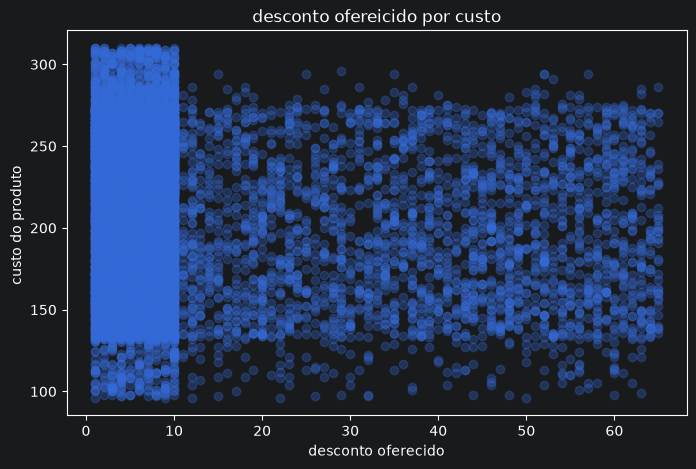

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(
     df['Discount_offered'], df['Cost_of_the_Product'],
     alpha = 0.3
)
plt.title("desconto ofereicido por custo")
plt.xlabel('desconto oferecido', fontsize=10)
plt.ylabel('custo do produto ', fontsize=10)
plt.show()

In [27]:

modelo_normal = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_split=10, random_state=42
)
modelo_normal.fit(X_train, y_train)
previsao = modelo_normal.predict(X_test)
acuracia = accuracy_score(y_test,previsao)
print(f" a acuracia foi de {previsao * 100:.2f}%")

 a acuracia foi de 67.59%
